# Лабораторна робота №4: Model Selection and Hyperparameter Tuning (Home Credit)

**Мета:** навчитись порівнювати різні алгоритми машинного навчання, підбирати їхні гіперпараметри та обґрунтовувати вибір моделі для практичного застосування.

**Задача та дані:** ті самі, що й у лабораторних №2 та №3: за анкетою позичальника передбачити, чи матиме він труднощі з поверненням кредиту (`TARGET = 1`). Змагання Kaggle [Home Credit Default Risk](https://www.kaggle.com/c/home-credit-default-risk/data), використано лише таблиці `application_train.csv` та `application_test.csv`.

**Зв'язок із лабораторною №3.** Ноутбук є її продовженням. Незмінними лишаються **розділення** даних (80/20, `stratify`, `random_state=42`), **метрика** ROC-AUC на валідації та **підсумковий набір ознак** лабораторної №3 (сім груп змін). Змінюється головне: замість одного дерева зі стандартними параметрами порівнюємо **п'ять алгоритмів** із курсу та підбираємо їм гіперпараметри.

| Модель | Лекція курсу |
|---|---|
| Логістична регресія (Logistic Regression) | №3 |
| Дерево рішень (Decision Tree) | №7 |
| Випадковий ліс (Random Forest) | №7 |
| Градієнтний бустинг (Gradient Boosting) | №7 |
| Нейронна мережа (багатошаровий перцептрон, оптимізатор Adam) | №10 |

Розвідувальний аналіз даних та експерименти з ознаками повторювати не потрібно: вони докладно розібрані в [лабораторній №3](https://github.com/valera99686/ml-lab3), а тут використовується її підсумковий результат.

**Бібліотеки:** numpy, pandas, matplotlib, scipy, scikit-learn

**План ноутбука:**
1. Завантаження даних
2. Підготовка ознак (результат лабораторної №3)
3. Схема порівняння моделей
4. Логістична регресія
5. Дерево рішень
6. Випадковий ліс
7. Градієнтний бустинг
8. Нейронна мережа
9. Порівняння моделей
10. Аналіз результатів та вибір найкращої моделі
11. Прогноз для тестових даних та submission-файл
12. Результат на Kaggle (Late Submission)

---

## 1. Завантаження даних

In [1]:
# Імпорт модулів для роботи зі шляхами, часом і попередженнями
import os
import time
import warnings

# Імпорт бібліотек NumPy і Pandas для роботи з даними
import numpy as np
import pandas as pd

# Імпорт модуля matplotlib.pyplot для побудови графіків
import matplotlib.pyplot as plt

# Розподіли для випадкового пошуку гіперпараметрів (SciPy встановлюється разом зі scikit-learn)
from scipy.stats import loguniform, randint

# Імпорт scikit-learn: розділення, пошук гіперпараметрів, обробка даних
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

# Імпорт п'яти моделей
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

# Імпорт метрик та засобу оцінки важливості ознак
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning

# Вмикаємо відображення графіків безпосередньо в ноутбуці
%matplotlib inline

# Попередження про недостатнє число ітерацій не виводимо: збіжність перевіряємо явно (n_iter_)
warnings.filterwarnings('ignore', category=ConvergenceWarning)

# Єдине значення для генератора випадкових чисел — щоб результати відтворювалися
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Єдиний стиль оформлення графіків для всього ноутбука
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# Виводимо версії бібліотек — фіксуємо оточення, в якому ноутбук був виконаний
print(f"NumPy:        {np.__version__}")
print(f"Pandas:       {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"Matplotlib:   {plt.matplotlib.__version__}")
print(f"Ядер процесора: {os.cpu_count()}")

NumPy:        2.5.3
Pandas:       3.0.6
scikit-learn: 1.9.1
Matplotlib:   3.11.2
Ядер процесора: 16


In [2]:
# --- Завантаження application_train.csv та application_test.csv ---

# Список каталогів, у яких шукаємо файли даних.
# Такий перебір дозволяє виконати ноутбук без змін і локально, і в Google Colab, і на Kaggle.
SEARCH_DIRS = [
    'data',                                       # локальний запуск: файли у підкаталозі ./data
    '.',                                          # файли лежать поруч із ноутбуком
    '/content',                                   # Google Colab: файли завантажені у сесію
    '/kaggle/input/home-credit-default-risk',     # Kaggle: дані змагання
]


def find_file(filename):
    """Повертає шлях до файлу даних, знайденого в одному з каталогів SEARCH_DIRS."""
    # Послідовно перебираємо каталоги-кандидати
    for d in SEARCH_DIRS:
        path = os.path.join(d, filename)
        # Якщо файл існує — повертаємо перший знайдений шлях
        if os.path.exists(path):
            return path
    # Якщо ніде не знайшли — повідомляємо зрозумілою помилкою
    raise FileNotFoundError(
        f"Не знайдено {filename}. Покладіть файл в один із каталогів: {SEARCH_DIRS}"
    )


# Читаємо навчальну таблицю (є колонка TARGET) та тестову (колонки TARGET немає)
train = pd.read_csv(find_file('application_train.csv'))
test = pd.read_csv(find_file('application_test.csv'))

print(f"application_train: {train.shape[0]} рядків, {train.shape[1]} колонок")
print(f"application_test:  {test.shape[0]} рядків, {test.shape[1]} колонок")

application_train: 307511 рядків, 122 колонок
application_test:  48744 рядків, 121 колонок


## 2. Підготовка ознак (результат лабораторної №3)

### 2.1 Розділення даних

Те саме розділення, що й раніше: 80 % — навчальна частина, 20 % — валідаційна, зі стратифікацією за ціллю та `random_state=42`. **Валідаційну вибірку не використовуємо для підбору гіперпараметрів**: підбір виконуємо крос-валідацією всередині навчальної частини (розділ 3), а на валідації лише один раз оцінюємо вже готові моделі. Інакше оцінка якості була б завищеною.

In [3]:
# --- 2.1 Розділення на навчальну та валідаційну частини (як у лабораторних №2 та №3) ---

# Цільова змінна та ознаки (ідентифікатор SK_ID_CURR не є ознакою)
y = train['TARGET']
X = train.drop(columns=['TARGET', 'SK_ID_CURR'])
X_test = test.drop(columns=['SK_ID_CURR'])
test_ids = test['SK_ID_CURR']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Навчальна частина:   {X_train.shape[0]} рядків, частка класу 1: {y_train.mean() * 100:.2f} %")
print(f"Валідаційна частина: {X_val.shape[0]} рядків, частка класу 1: {y_val.mean() * 100:.2f} %")

Навчальна частина:   246008 рядків, частка класу 1: 8.07 %
Валідаційна частина: 61503 рядків, частка класу 1: 8.07 %


### 2.2 Ознаки з лабораторної №3

У лабораторній №3 перевірено дев'ять груп змін ознак і за наперед заданим правилом залишено сім: **A** (аномалія `DAYS_EMPLOYED`), **C** (відношення сум), **D** (агрегати `EXT_SOURCE_*`), **F** (підрахунки прапорців), **H2** (освіта як порядкова ознака), **G2** (видалення дублів `_MODE`/`_MEDI`), **H1** (об'єднання рідкісних категорій). Тут той самий код, без змін: з 120 початкових ознак виходить 107.

In [4]:
# --- 2.2 Підсумковий набір ознак із лабораторної №3 ---
# Сім груп змін, відібраних у лабораторній №3 (A, C, D, F, H2, G2, H1). Кожна працює для кожного рядка
# окремо; лише списки колонок і категорій визначаються за навчальною частиною.

def safe_div(a, b):
    """Ділення, яке замість нескінченності та помилки повертає пропуск, якщо знаменник дорівнює нулю."""
    return a / b.replace(0, np.nan)


def fe_anomaly(X):
    """A. DAYS_EMPLOYED = 365243 (службова позначка) -> пропуск + прапорець аномалії."""
    X = X.copy()
    X['DAYS_EMPLOYED_ANOM'] = (X['DAYS_EMPLOYED'] == 365243).astype(int)
    X['DAYS_EMPLOYED'] = X['DAYS_EMPLOYED'].replace(365243, np.nan)
    return X


def fe_ratios(X):
    """C. Відношення сум та відносні показники."""
    X = X.copy()
    employed = X['DAYS_EMPLOYED'].replace(365243, np.nan)       # стаж без службової позначки
    X['CREDIT_INCOME_RATIO'] = safe_div(X['AMT_CREDIT'], X['AMT_INCOME_TOTAL'])
    X['ANNUITY_INCOME_RATIO'] = safe_div(X['AMT_ANNUITY'], X['AMT_INCOME_TOTAL'])
    X['CREDIT_TERM'] = safe_div(X['AMT_CREDIT'], X['AMT_ANNUITY'])
    X['GOODS_CREDIT_RATIO'] = safe_div(X['AMT_GOODS_PRICE'], X['AMT_CREDIT'])
    X['EMPLOYED_BIRTH_RATIO'] = safe_div(employed, X['DAYS_BIRTH'])
    X['INCOME_PER_PERSON'] = safe_div(X['AMT_INCOME_TOTAL'], X['CNT_FAM_MEMBERS'])
    return X


def fe_ext_source(X):
    """D. Агрегати трьох зовнішніх оцінок."""
    X = X.copy()
    ext = X[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']]
    X['EXT_MEAN'] = ext.mean(axis=1)                       # середнє наявних оцінок
    X['EXT_MIN'] = ext.min(axis=1)
    X['EXT_MAX'] = ext.max(axis=1)
    X['EXT_PROD'] = ext.prod(axis=1, min_count=1)          # добуток наявних оцінок
    X['EXT_MISSING'] = ext.isna().sum(axis=1)              # скільки оцінок відсутні
    return X


def fe_flag_counts(X):
    """F. Підрахунки прапорців: документи, контакти, невідповідності адрес, запити до бюро."""
    X = X.copy()
    documents = [c for c in X.columns if c.startswith('FLAG_DOCUMENT_')]
    contacts = ['FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL']
    addresses = ['REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION',
                 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY']
    bureau = [c for c in X.columns if c.startswith('AMT_REQ_CREDIT_BUREAU_')]
    X['DOCUMENT_COUNT'] = X[documents].sum(axis=1)
    X['CONTACT_COUNT'] = X[contacts].sum(axis=1)
    X['ADDRESS_MISMATCH_COUNT'] = X[addresses].sum(axis=1)
    X['BUREAU_REQ_TOTAL'] = X[bureau].sum(axis=1, min_count=1)
    return X


# Порядок рівнів освіти (від нижчого до вищого)
EDUCATION_ORDER = {'Lower secondary': 0, 'Secondary / secondary special': 1, 'Incomplete higher': 2,
                   'Higher education': 3, 'Academic degree': 4}


def fe_education(X):
    """H2. Освіта як порядкове число замість п'яти one-hot колонок."""
    X = X.copy()
    X['EDUCATION_LEVEL'] = X['NAME_EDUCATION_TYPE'].map(EDUCATION_ORDER)
    return X.drop(columns=['NAME_EDUCATION_TYPE'])


# Колонки та категорії, що визначаються ЛИШЕ за навчальною частиною
categorical_modes = ['FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']
duplicate_cols = [c for c in X_train.columns if c.endswith(('_MODE', '_MEDI')) and c not in categorical_modes]

frequent_categories = {}
for c in X_train.select_dtypes(exclude='number').columns:
    freq = X_train[c].value_counts(normalize=True)
    frequent_categories[c] = freq[freq >= 0.01].index.tolist()


def fe_drop_duplicates(X):
    """G2. Видалення дублів _MODE та _MEDI."""
    return X.drop(columns=duplicate_cols)


def fe_rare_categories(X):
    """H1. Рідкісні категорії -> 'Other' (пропуски лишаються пропусками)."""
    X = X.copy()
    for c, keep in frequent_categories.items():
        if c in X.columns:
            X[c] = X[c].where(X[c].isin(keep) | X[c].isna(), 'Other')
    return X


def final_transform(X):
    """Підсумковий набір ознак лабораторної №3: послідовне застосування відібраних груп змін."""
    for step in (fe_anomaly, fe_ratios, fe_ext_source, fe_flag_counts, fe_education, fe_drop_duplicates, fe_rare_categories):
        X = step(X)
    return X


# Ознаки навчальної, валідаційної та тестової частин у підсумковому наборі
X_train_fe = final_transform(X_train)
X_val_fe = final_transform(X_val)
X_test_fe = final_transform(X_test)

print(f"Ознак було: {X_train.shape[1]}, стало: {X_train_fe.shape[1]}")
print(f"Форми: навчальна {X_train_fe.shape}, валідаційна {X_val_fe.shape}, тестова {X_test_fe.shape}")

Ознак було: 120, стало: 107
Форми: навчальна (246008, 107), валідаційна (61503, 107), тестова (48744, 107)


### 2.3 Обробка пропусків і категорій

Обробка та сама, що в лабораторних №2–3: числові ознаки — пропуски заповнюємо медіаною, категоріальні — категорією `Unknown` і one-hot кодуванням. Параметри обробки (медіани, список категорій) визначаємо **лише за навчальною частиною**. Вони не використовують ціль, тому один раз підготовлена матриця безпечна для крос-валідації в наступних розділах.

Масштабування потрібне лише логістичній регресії та нейронній мережі (вони чутливі до шкали ознак; дерева — ні), тому `StandardScaler` додаємо в їхні конвеєри окремо.

In [5]:
# --- 2.3 Обробка пропусків та кодування категорій ---

# Типи ознак у підсумковому наборі
numeric_cols = X_train_fe.select_dtypes(include='number').columns.tolist()
categorical_cols = X_train_fe.select_dtypes(exclude='number').columns.tolist()

preprocessor = ColumnTransformer([
    # Числові ознаки: пропуски -> медіана навчальної частини
    ('num', SimpleImputer(strategy='median'), numeric_cols),
    # Категоріальні ознаки: пропуск -> "Unknown", потім one-hot кодування
    ('cat', make_pipeline(SimpleImputer(strategy='constant', fill_value='Unknown'),
                          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), categorical_cols),
])

# Параметри обробки навчаємо на навчальній частині; до валідації та тесту їх лише застосовуємо
A_train = preprocessor.fit_transform(X_train_fe)
A_val = preprocessor.transform(X_val_fe)
A_test = preprocessor.transform(X_test_fe)

# Назви колонок після обробки (для інтерпретації моделей)
feature_names = [n.split('__', 1)[1] for n in preprocessor.get_feature_names_out()]

print(f"Числових ознак: {len(numeric_cols)}, категоріальних: {len(categorical_cols)}")
print(f"Матриці після обробки: навчальна {A_train.shape}, валідаційна {A_val.shape}, тестова {A_test.shape}")
print(f"Пропусків після обробки: {np.isnan(A_train).sum()} / {np.isnan(A_val).sum()} / {np.isnan(A_test).sum()}")

Числових ознак: 92, категоріальних: 15
Матриці після обробки: навчальна (246008, 181), валідаційна (61503, 181), тестова (48744, 181)
Пропусків після обробки: 0 / 0 / 0


## 3. Схема порівняння моделей

Для кожної з п'яти моделей виконуємо однакові кроки:

1. **Параметри за замовчуванням.** Навчаємо на всій навчальній частині, оцінюємо ROC-AUC на валідації, фіксуємо час навчання.
2. **Підбір гіперпараметрів** (лекція №6). Для дерева — повний перебір за сіткою (**Grid Search**), для решти — **Random Search**: випадкові конфігурації з заданих розподілів. Кожну конфігурацію оцінюємо **3-кратною стратифікованою крос-валідацією** за ROC-AUC на підвибірці з 60 000 рядків навчальної частини. Підвибірка потрібна, щоб пошук (десятки конфігурацій × 3 розбиття) виконувався за хвилини, а не години. **Валідаційна вибірка в пошуку не бере участі.**
3. **Підсумкове навчання.** Найкращу за крос-валідацією конфігурацію навчаємо на всій навчальній частині й **один раз** оцінюємо на валідації.
4. **Важливість ознак.** Для кожної моделі — зручним для неї способом (коефіцієнти, важливість за gini, перестановкова важливість).

**Обмеження.** Оптимальні параметри, знайдені на підвибірці, можуть бути трохи консервативнішими, ніж на всіх даних (більше даних дозволяє складнішу модель). Для порівняння моделей між собою це прийнятно: усі вони шукаються за однаковою схемою.

In [6]:
# --- 3. Допоміжні засоби: пошук гіперпараметрів, навчання, облік результатів ---

from sklearn.base import clone

# Підвибірка навчальної частини для пошуку (стратифікована: частка класу 1 зберігається)
SEARCH_SIZE = 60000
A_search, _, y_search, _ = train_test_split(
    A_train, y_train, train_size=SEARCH_SIZE, stratify=y_train, random_state=RANDOM_STATE
)

# 3-кратна стратифікована крос-валідація, однакова для всіх моделей
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
print(f"Підвибірка для пошуку: {A_search.shape[0]} рядків, частка класу 1: {y_search.mean() * 100:.2f} %")

results = []     # зведена таблиця: один рядок = одна модель на одному етапі
searches = {}    # підсумки пошуку гіперпараметрів кожної моделі
fitted = {}      # навчені моделі та їхні ймовірності на валідації: fitted[(модель, етап)] = (модель, ймовірності)


def fit_and_score(family, stage, model):
    """Навчає модель на всій навчальній частині та оцінює на валідації."""
    start = time.time()
    model.fit(A_train, y_train)
    fit_time = time.time() - start

    start = time.time()
    proba = model.predict_proba(A_val)[:, 1]
    predict_time = time.time() - start

    auc = roc_auc_score(y_val, proba)
    results.append({'Модель': family, 'Етап': stage, 'ROC-AUC': auc,
                    'Навчання, с': fit_time, 'Прогноз, с': predict_time})
    fitted[(family, stage)] = (model, proba)
    print(f"{family} | {stage}: ROC-AUC на валідації = {auc:.4f}, навчання {fit_time:.1f} с, прогноз {predict_time:.2f} с")
    return model


def tune(family, estimator, param_space, method='random', n_iter=None):
    """Підбір гіперпараметрів крос-валідацією на підвибірці; повертає найкращі параметри."""
    if method == 'grid':
        search = GridSearchCV(estimator, param_space, scoring='roc_auc', cv=cv,
                              n_jobs=-1, refit=False, return_train_score=True)
    else:
        search = RandomizedSearchCV(estimator, param_space, n_iter=n_iter, scoring='roc_auc', cv=cv,
                                    n_jobs=-1, random_state=RANDOM_STATE, refit=False, return_train_score=True)
    start = time.time()
    search.fit(A_search, y_search)
    search_time = time.time() - start

    table = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
    best = table.iloc[0]
    searches[family] = {'method': method, 'candidates': len(table), 'time': search_time,
                        'cv_auc': best['mean_test_score'], 'cv_train_auc': best['mean_train_score'],
                        'params': search.best_params_}

    print(f"{family}: {'Grid' if method == 'grid' else 'Random'} Search, конфігурацій: {len(table)}, "
          f"час {search_time:.0f} с")
    print(f"Найкраща: AUC крос-валідації = {best['mean_test_score']:.4f} "
          f"(на навчальних частинах розбиття {best['mean_train_score']:.4f})")
    print("Параметри:", {k.split('__')[-1]: (round(v, 5) if isinstance(v, float) else v) for k, v in search.best_params_.items()})
    print("\nП'ять найкращих конфігурацій (AUC крос-валідації / на навчальних частинах):")
    for rank, (_, row) in enumerate(table.head(5).iterrows(), 1):
        short = {k.split('__')[-1]: (round(v, 4) if isinstance(v, float) else v) for k, v in row['params'].items()}
        print(f"  {rank}. {row['mean_test_score']:.4f} / {row['mean_train_score']:.4f}  {short}")
    return search.best_params_


def top_bar(series, title, xlabel, n=15, signed=False):
    """Горизонтальна діаграма n найважливіших ознак."""
    top = series.reindex(series.abs().sort_values(ascending=False).index).head(n).iloc[::-1] if signed \
        else series.sort_values(ascending=False).head(n).iloc[::-1]
    colors = ['#d62728' if v > 0 else '#1f77b4' for v in top.values] if signed else '#1f77b4'
    fig, ax = plt.subplots(figsize=(9, 5.8))
    ax.barh(top.index, top.values, color=colors)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    return top


importances = {}   # важливість ознак кожної моделі (для порівняння в розділі 9)

Підвибірка для пошуку: 60000 рядків, частка класу 1: 8.07 %


## 4. Логістична регресія

**Модель** (лекція №3): лінійна комбінація ознак, перетворена сигмоїдою на ймовірність класу 1; ваги знаходяться мінімізацією логістичної функції втрат. Це найпростіша й найінтерпретованіша модель серед п'яти. Вона чутлива до шкали ознак, тому перед нею стоїть `StandardScaler`.

**Гіперпараметри для підбору:**
- `C` — обернена сила L2-регуляризації (менше `C` — сильніша регуляризація, простіша модель); пробуємо від 0.0001 до 10 на логарифмічній шкалі;
- `class_weight` — без ваг або `balanced` (ваги класів обернено пропорційні частоті; корисно при дисбалансі 8 %).

In [7]:
# --- 4.1 Логістична регресія: параметри за замовчуванням ---

lr_estimator = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
lr_default = fit_and_score('Логістична регресія', 'За замовчуванням', clone(lr_estimator))
print(f"Ітерацій оптимізатора: {lr_default[-1].n_iter_[0]} (ліміт 500) — модель {'збіглась' if lr_default[-1].n_iter_[0] < 500 else 'НЕ збіглась'}")

Логістична регресія | За замовчуванням: ROC-AUC на валідації = 0.7514, навчання 4.5 с, прогноз 0.11 с
Ітерацій оптимізатора: 45 (ліміт 500) — модель збіглась


In [8]:
# --- 4.2 Логістична регресія: підбір гіперпараметрів (Random Search) ---

lr_space = {
    'logisticregression__C': loguniform(1e-4, 1e1),                  # сила регуляризації, логарифмічна шкала
    'logisticregression__class_weight': [None, 'balanced'],          # ваги класів
}
lr_best = tune('Логістична регресія', lr_estimator, lr_space, n_iter=15)

lr_tuned = fit_and_score('Логістична регресія', 'Підібрані параметри', clone(lr_estimator).set_params(**lr_best))

Логістична регресія: Random Search, конфігурацій: 15, час 25 с
Найкраща: AUC крос-валідації = 0.7446 (на навчальних частинах розбиття 0.7556)
Параметри: {'C': np.float64(0.0005), 'class_weight': 'balanced'}

П'ять найкращих конфігурацій (AUC крос-валідації / на навчальних частинах):
  1. 0.7446 / 0.7556  {'C': np.float64(0.0005), 'class_weight': 'balanced'}
  2. 0.7445 / 0.7563  {'C': np.float64(0.0008), 'class_weight': 'balanced'}
  3. 0.7445 / 0.7563  {'C': np.float64(0.0008), 'class_weight': 'balanced'}
  4. 0.7444 / 0.7563  {'C': np.float64(0.0075), 'class_weight': None}
  5. 0.7443 / 0.7534  {'C': np.float64(0.0002), 'class_weight': 'balanced'}


Логістична регресія | Підібрані параметри: ROC-AUC на валідації = 0.7509, навчання 3.8 с, прогноз 0.13 с


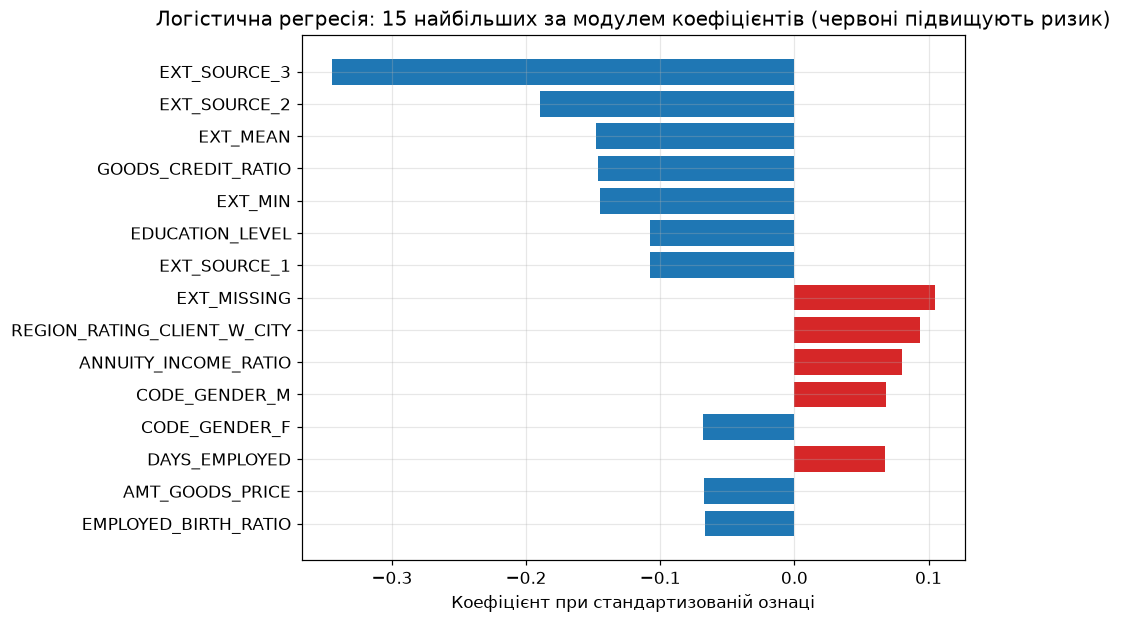

Найсильніше підвищують ризик дефолту:
  EXT_MISSING                      +0.104
  REGION_RATING_CLIENT_W_CITY      +0.094
  ANNUITY_INCOME_RATIO             +0.081
  CODE_GENDER_M                    +0.068
  DAYS_EMPLOYED                    +0.068
Найсильніше знижують ризик дефолту:
  EXT_SOURCE_3                     -0.345
  EXT_SOURCE_2                     -0.189
  EXT_MEAN                         -0.148
  GOODS_CREDIT_RATIO               -0.147
  EXT_MIN                          -0.145


In [9]:
# --- 4.3 Логістична регресія: коефіцієнти ---

# Ознаки стандартизовані, тому коефіцієнти порівнянні між собою: це зміна логарифма шансів
# на дефолт при зростанні ознаки на одне стандартне відхилення
coefficients = pd.Series(lr_tuned.named_steps['logisticregression'].coef_[0], index=feature_names)
importances['Логістична регресія'] = coefficients.abs()

top_bar(coefficients, 'Логістична регресія: 15 найбільших за модулем коефіцієнтів (червоні підвищують ризик)',
        'Коефіцієнт при стандартизованій ознаці', signed=True)

print("Найсильніше підвищують ризик дефолту:")
for name, value in coefficients.sort_values(ascending=False).head(5).items():
    print(f"  {name:<32} {value:+.3f}")
print("Найсильніше знижують ризик дефолту:")
for name, value in coefficients.sort_values().head(5).items():
    print(f"  {name:<32} {value:+.3f}")

**Результат.** Параметри за замовчуванням (`C = 1`) дали ROC-AUC 0.7514, підібрані (`C = 0.0005`, `class_weight='balanced'`) — 0.7509. Різниця −0.0005 лежить у межах шуму. П'ять найкращих конфігурацій відрізняються лише на 0.0003 (0.7443–0.7446), тобто оптимум плоский: логістичній регресії зі 181 ознакою на 246 тисячах рядків майже байдуже, наскільки сильно її регуляризувати. Це модель із великим зсувом і малою дисперсією: вона не перенавчується (AUC на навчальних і валідаційних частинах розбиття відрізняється лише на 0.011), але й не вміє відтворювати нелінійні залежності.

**Інтерпретація.** Коефіцієнти — найпрозоріша частина всієї лабораторної:
- найсильніше **знижують** ризик дефолту зовнішні оцінки: `EXT_SOURCE_3` (−0.345), `EXT_SOURCE_2` (−0.189), створені нами `EXT_MEAN` (−0.148) та `EXT_MIN` (−0.145), а також `GOODS_CREDIT_RATIO` (−0.147);
- найсильніше **підвищують**: кількість відсутніх зовнішніх оцінок `EXT_MISSING` (+0.104), рейтинг регіону `REGION_RATING_CLIENT_W_CITY` (+0.094) та навантаження `ANNUITY_INCOME_RATIO` (+0.081).

Знаки відповідають здоровому глузду: вища зовнішня оцінка — нижчий ризик, більший платіж відносно доходу — вищий. П'ять із десяти виведених вище ознак створено в лабораторній №3, тож вони працюють і для лінійної моделі. Коефіцієнти колінеарних ознак (`EXT_SOURCE_*` та їхні агрегати) ділять між собою спільний ефект, тому читати окремий коефіцієнт слід обережно.

## 5. Дерево рішень

**Модель** (лекція №7): послідовність розбиттів за порогами ознак, що мінімізують неоднорідність (Gini). Без обмежень дерево росте, доки листи не стануть чистими, і запам'ятовує навчальні дані (так було в лабораторній №3).

**Гіперпараметри для підбору** (перебір за сіткою, бо їх небагато):
- `max_depth` — максимальна глибина дерева;
- `min_samples_leaf` — мінімальна кількість рядків у листі: чим більше, тим стабільніша ймовірність у листі.

Обидва обмежують складність дерева, тобто діють як регуляризація.

In [10]:
# --- 5.1 Дерево рішень: параметри за замовчуванням ---

dt_default = fit_and_score('Дерево рішень', 'За замовчуванням', DecisionTreeClassifier(random_state=RANDOM_STATE))
print(f"Глибина дерева: {dt_default.get_depth()}, листів: {dt_default.get_n_leaves()}")
print("У лабораторній №3 це дерево на тих самих ознаках мало ROC-AUC 0.5432: результат відтворено.")

Дерево рішень | За замовчуванням: ROC-AUC на валідації = 0.5432, навчання 37.5 с, прогноз 0.10 с
Глибина дерева: 60, листів: 18873
У лабораторній №3 це дерево на тих самих ознаках мало ROC-AUC 0.5432: результат відтворено.


In [11]:
# --- 5.2 Дерево рішень: підбір гіперпараметрів (Grid Search) ---

dt_grid = {
    'max_depth': [3, 4, 5, 6, 7, 8, 10, 12],
    'min_samples_leaf': [1, 20, 50, 100, 300],
}
dt_best = tune('Дерево рішень', DecisionTreeClassifier(random_state=RANDOM_STATE), dt_grid, method='grid')

dt_tuned = fit_and_score('Дерево рішень', 'Підібрані параметри',
                         DecisionTreeClassifier(random_state=RANDOM_STATE, **dt_best))
print(f"Глибина дерева: {dt_tuned.get_depth()}, листів: {dt_tuned.get_n_leaves()}")

Дерево рішень: Grid Search, конфігурацій: 40, час 44 с
Найкраща: AUC крос-валідації = 0.7157 (на навчальних частинах розбиття 0.7346)
Параметри: {'max_depth': 5, 'min_samples_leaf': 300}

П'ять найкращих конфігурацій (AUC крос-валідації / на навчальних частинах):
  1. 0.7157 / 0.7346  {'max_depth': 5, 'min_samples_leaf': 300}
  2. 0.7134 / 0.7246  {'max_depth': 4, 'min_samples_leaf': 100}
  3. 0.7134 / 0.7248  {'max_depth': 4, 'min_samples_leaf': 50}
  4. 0.7133 / 0.7245  {'max_depth': 4, 'min_samples_leaf': 300}
  5. 0.7132 / 0.7356  {'max_depth': 5, 'min_samples_leaf': 100}


Дерево рішень | Підібрані параметри: ROC-AUC на валідації = 0.7273, навчання 17.8 с, прогноз 0.09 с
Глибина дерева: 5, листів: 32


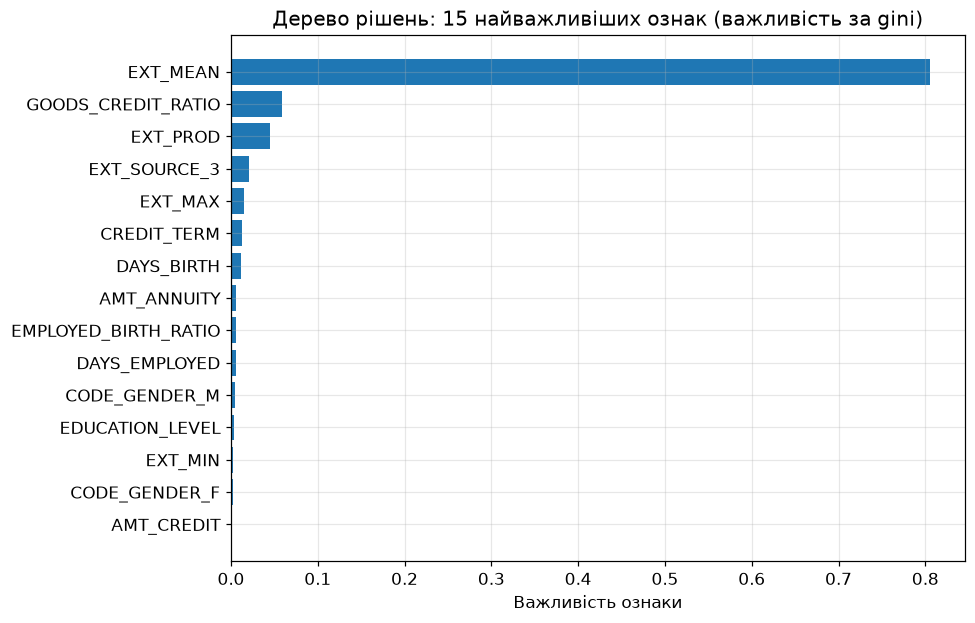

Перші три рівні підібраного дерева:

|--- EXT_MEAN <= 0.394
|   |--- EXT_MEAN <= 0.252
|   |   |--- EXT_PROD <= 0.023
|   |   |   |--- GOODS_CREDIT_RATIO <= 0.863
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- GOODS_CREDIT_RATIO >  0.863
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- EXT_PROD >  0.023
|   |   |   |--- DAYS_BIRTH <= -18216.500
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- DAYS_BIRTH >  -18216.500
|   |   |   |   |--- truncated branch of depth 2
|   |--- EXT_MEAN >  0.252
|   |   |--- GOODS_CREDIT_RATIO <= 0.826
|   |   |   |--- CREDIT_TERM <= 21.453
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- CREDIT_TERM >  21.453
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- GOODS_CREDIT_RATIO >  0.826
|   |   |   |--- EXT_SOURCE_3 <= 0.223
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- EXT_SOURCE_3 >  0.223
|   |   |   |   |--- truncated branch of depth 2
|--- EXT_MEAN >  0.3

In [12]:
# --- 5.3 Дерево рішень: важливість ознак та перші розбиття ---

dt_importance = pd.Series(dt_tuned.feature_importances_, index=feature_names)
importances['Дерево рішень'] = dt_importance
top_bar(dt_importance, 'Дерево рішень: 15 найважливіших ознак (важливість за gini)', 'Важливість ознаки')

# Перші три рівні дерева у вигляді правил: так дерево «приймає рішення»
print("Перші три рівні підібраного дерева:\n")
print(export_text(dt_tuned, feature_names=feature_names, max_depth=3, decimals=3))

**Результат.** Це найяскравіший приклад впливу підбору гіперпараметрів. Дерево з параметрами за замовчуванням має ROC-AUC 0.5432 (глибина 60, 18873 листів — той самий випадок, що в лабораторній №3), а підібране — **0.7273** (глибина 5, `min_samples_leaf = 300`, лише 32 листи). Приріст **+0.1840**. Обмеження глибини та розміру листа перетворюють прогноз у листі на середнє за сотнями рядків замість «0 або 1». Усі п'ять найкращих конфігурацій — неглибокі дерева (глибина 4–5, AUC крос-валідації 0.7132–0.7157), різниця між ними в межах шуму. Результат узгоджується з допоміжною перевіркою лабораторної №3: на глибині 5 там вийшло 0.7270.

**Інтерпретація.** Дерево — єдина модель, яку можна «прочитати» як набір правил (див. вивід вище). У корені стоїть `EXT_MEAN` — ознака, створена нами в лабораторній №3, а на перших рівнях також `EXT_PROD`, `EXT_MAX`, `GOODS_CREDIT_RATIO`, `CREDIT_TERM`, `EXT_SOURCE_3`, `DAYS_BIRTH` та `DAYS_EMPLOYED`. Ціна прозорості — якість: 0.7273 на 0.039 нижче за найкращу модель, до того ж дерево нестабільне, бо невелика зміна даних може змінити розбиття.

## 6. Випадковий ліс

**Модель** (лекція №7): ансамбль багатьох глибоких дерев, кожне з яких навчається на випадковій підвибірці рядків (**bagging**) і розглядає на кожному розбитті лише випадкову частину ознак. Прогнози дерев усереднюються, тому шум окремих дерев гасне: ліс майже не перенавчається, хоча кожне дерево перенавчене.

**Гіперпараметри для підбору:**
- `n_estimators` — кількість дерев;
- `max_depth` — глибина кожного дерева;
- `min_samples_leaf` — мінімальна кількість рядків у листі;
- `max_features` — частка ознак, що розглядаються на кожному розбитті.

In [13]:
# --- 6.1 Випадковий ліс: параметри за замовчуванням (100 дерев без обмеження глибини) ---

rf_default = fit_and_score('Випадковий ліс', 'За замовчуванням',
                           RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE))

Випадковий ліс | За замовчуванням: ROC-AUC на валідації = 0.7248, навчання 32.9 с, прогноз 1.03 с


In [14]:
# --- 6.2 Випадковий ліс: підбір гіперпараметрів (Random Search) ---

rf_space = {
    'n_estimators': randint(100, 401),
    'max_depth': [6, 8, 10, 12, 15, 20, None],
    'min_samples_leaf': [1, 5, 20, 50, 100],
    'max_features': ['sqrt', 0.3, 0.5],
}
# Пошук розпаралелюємо за конфігураціями, тому кожен окремий ліс навчається в одному потоці
rf_best = tune('Випадковий ліс', RandomForestClassifier(n_jobs=1, random_state=RANDOM_STATE), rf_space, n_iter=16)

# Остаточний ліс навчаємо вже на всіх ядрах
rf_tuned = fit_and_score('Випадковий ліс', 'Підібрані параметри',
                         RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE, **rf_best))

Випадковий ліс: Random Search, конфігурацій: 16, час 714 с
Найкраща: AUC крос-валідації = 0.7426 (на навчальних частинах розбиття 0.8771)
Параметри: {'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'n_estimators': 234}

П'ять найкращих конфігурацій (AUC крос-валідації / на навчальних частинах):
  1. 0.7426 / 0.8771  {'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'n_estimators': 234}
  2. 0.7418 / 0.9270  {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'n_estimators': 171}
  3. 0.7398 / 0.9717  {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 314}
  4. 0.7397 / 0.8254  {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 191}
  5. 0.7396 / 0.8754  {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 50, 'n_estimators': 287}


Випадковий ліс | Підібрані параметри: ROC-AUC на валідації = 0.7500, навчання 43.9 с, прогноз 0.66 с


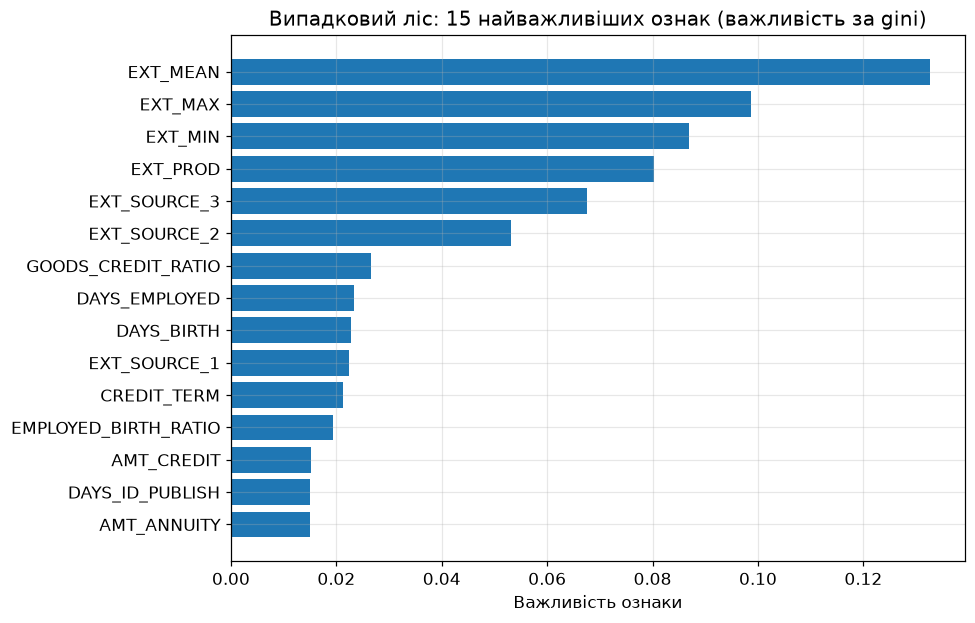

AMT_ANNUITY             0.015017
DAYS_ID_PUBLISH         0.015018
AMT_CREDIT              0.015101
EMPLOYED_BIRTH_RATIO    0.019365
CREDIT_TERM             0.021210
EXT_SOURCE_1            0.022399
DAYS_BIRTH              0.022741
DAYS_EMPLOYED           0.023258
GOODS_CREDIT_RATIO      0.026521
EXT_SOURCE_2            0.053118
EXT_SOURCE_3            0.067518
EXT_PROD                0.080197
EXT_MIN                 0.086930
EXT_MAX                 0.098605
EXT_MEAN                0.132595
dtype: float64

In [15]:
# --- 6.3 Випадковий ліс: важливість ознак ---

rf_importance = pd.Series(rf_tuned.feature_importances_, index=feature_names)
importances['Випадковий ліс'] = rf_importance
top_bar(rf_importance, 'Випадковий ліс: 15 найважливіших ознак (важливість за gini)', 'Важливість ознаки')

**Результат.** Параметри за замовчуванням (100 дерев без обмеження глибини, `min_samples_leaf = 1`) дали 0.7248, підібрані — **0.7500** (234 дерева, `max_depth = 12`, `min_samples_leaf = 20`, `max_features = 'sqrt'`): **+0.0252**. Приріст дало те саме, що й для одного дерева, — обмеження складності кожного дерева. Усереднення ансамблю робить ліс значно стійкішим за одне дерево (0.7248 проти 0.5432 за замовчуванням), але його дерева все ж надто глибокі.

**Ціна.** Пошук тривав **714 с (майже 12 хвилин)**, приблизно в 28 разів довше, ніж для логістичної регресії (25 с), а виграшу відносно неї немає (0.7500 проти 0.7509). Звертає на себе увагу розрив між AUC на навчальних і валідаційних частинах розбиття найкращої конфігурації: 0.8771 проти 0.7426, тобто близько 0.13, найбільший серед усіх моделей. Кожне дерево ліса запам'ятовує навчальні рядки, а усереднення лише частково це компенсує.

**Інтерпретація.** Важливість за gini (діаграма вище) очолюють `EXT_MEAN`, `EXT_MAX`, `EXT_MIN`, `EXT_PROD` та `EXT_SOURCE_3`: ліс «бачить» ті самі зовнішні оцінки, що й інші моделі. Важливість за gini завищує неперервні ознаки з багатьма різними значеннями, тому це орієнтир, а не точна міра.

## 7. Градієнтний бустинг

**Модель** (лекція №7): ансамбль **неглибоких** дерев, які будуються **послідовно**: кожне нове дерево навчається виправляти помилки попередніх (рухаючись у напрямку антиградієнта функції втрат, звідси назва). Використано `HistGradientBoostingClassifier` — реалізацію градієнтного бустингу над деревами, у якій значення ознак попередньо групуються в гістограми, завдяки чому вона працює швидко навіть на сотнях тисяч рядків (за тим самим принципом працюють LightGBM та XGBoost). Бустинг сам обробляє пропуски, а параметр `early_stopping` зупиняє додавання дерев, коли якість на внутрішній частині даних перестає зростати.

**Гіперпараметри для підбору:**
- `learning_rate` — внесок кожного дерева (менше — повільніше, але стабільніше навчання);
- `max_iter` — максимальна кількість дерев;
- `max_leaf_nodes` — складність кожного дерева;
- `min_samples_leaf` — мінімальна кількість рядків у листі;
- `l2_regularization` — штраф за великі значення в листах.

In [16]:
# --- 7.1 Градієнтний бустинг: параметри за замовчуванням ---

hgb_default = fit_and_score('Градієнтний бустинг', 'За замовчуванням',
                            HistGradientBoostingClassifier(random_state=RANDOM_STATE))
print(f"Побудовано дерев: {hgb_default.n_iter_}")

Градієнтний бустинг | За замовчуванням: ROC-AUC на валідації = 0.7662, навчання 10.3 с, прогноз 0.35 с
Побудовано дерев: 100


In [17]:
# --- 7.2 Градієнтний бустинг: підбір гіперпараметрів (Random Search) ---

hgb_space = {
    'learning_rate': loguniform(0.02, 0.2),
    'max_iter': randint(100, 701),
    'max_leaf_nodes': randint(8, 64),
    'min_samples_leaf': randint(20, 400),
    'l2_regularization': loguniform(1e-3, 1e1),
}
hgb_best = tune('Градієнтний бустинг',
                HistGradientBoostingClassifier(early_stopping=True, random_state=RANDOM_STATE), hgb_space, n_iter=24)

hgb_tuned = fit_and_score('Градієнтний бустинг', 'Підібрані параметри',
                          HistGradientBoostingClassifier(early_stopping=True, random_state=RANDOM_STATE, **hgb_best))
print(f"Побудовано дерев: {hgb_tuned.n_iter_}")

Градієнтний бустинг: Random Search, конфігурацій: 24, час 195 с
Найкраща: AUC крос-валідації = 0.7525 (на навчальних частинах розбиття 0.8101)
Параметри: {'l2_regularization': np.float64(0.70043), 'learning_rate': np.float64(0.12337), 'max_iter': 478, 'max_leaf_nodes': 12, 'min_samples_leaf': 250}

П'ять найкращих конфігурацій (AUC крос-валідації / на навчальних частинах):
  1. 0.7525 / 0.8101  {'l2_regularization': np.float64(0.7004), 'learning_rate': np.float64(0.1234), 'max_iter': 478, 'max_leaf_nodes': 12, 'min_samples_leaf': 250}
  2. 0.7519 / 0.7925  {'l2_regularization': np.float64(4.3379), 'learning_rate': np.float64(0.0363), 'max_iter': 487, 'max_leaf_nodes': 9, 'min_samples_leaf': 73}
  3. 0.7513 / 0.7875  {'l2_regularization': np.float64(0.8288), 'learning_rate': np.float64(0.0868), 'max_iter': 646, 'max_leaf_nodes': 8, 'min_samples_leaf': 246}
  4. 0.7508 / 0.8255  {'l2_regularization': np.float64(0.0106), 'learning_rate': np.float64(0.022), 'max_iter': 306, 'max_leaf_nodes

Градієнтний бустинг | Підібрані параметри: ROC-AUC на валідації = 0.7663, навчання 8.6 с, прогноз 0.44 с
Побудовано дерев: 101


Перестановкова важливість обчислена за 25 с


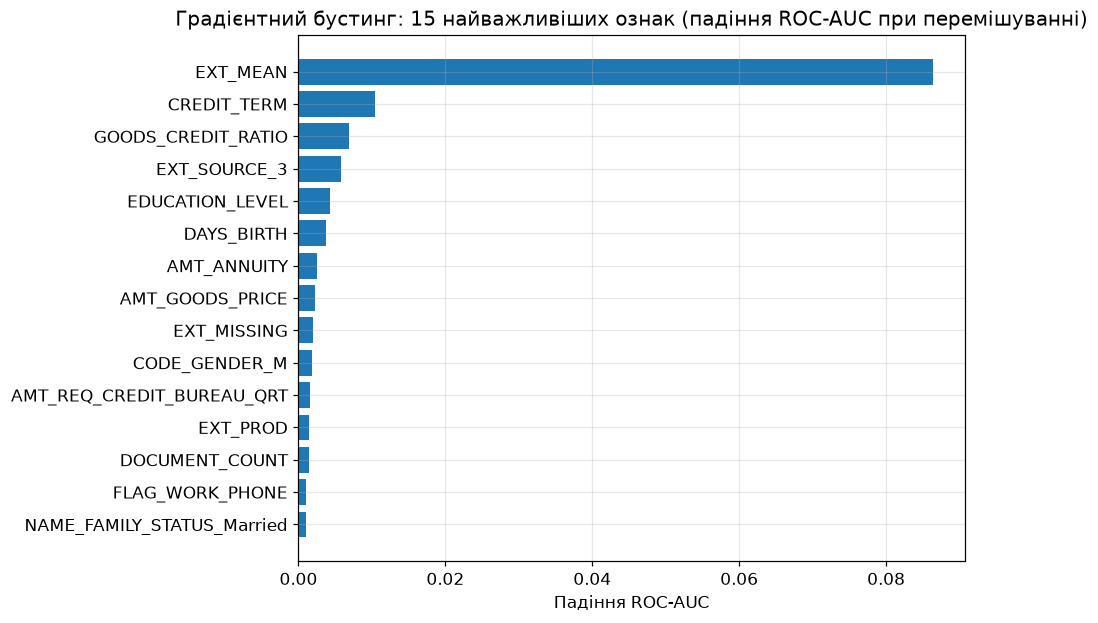

NAME_FAMILY_STATUS_Married    0.001063
FLAG_WORK_PHONE               0.001071
DOCUMENT_COUNT                0.001366
EXT_PROD                      0.001475
AMT_REQ_CREDIT_BUREAU_QRT     0.001530
CODE_GENDER_M                 0.001817
EXT_MISSING                   0.001960
AMT_GOODS_PRICE               0.002189
AMT_ANNUITY                   0.002465
DAYS_BIRTH                    0.003745
EDUCATION_LEVEL               0.004311
EXT_SOURCE_3                  0.005792
GOODS_CREDIT_RATIO            0.006886
CREDIT_TERM                   0.010449
EXT_MEAN                      0.086381
dtype: float64

In [18]:
# --- 7.3 Градієнтний бустинг: перестановкова важливість ознак ---

# У HistGradientBoosting немає вбудованої важливості, тому використовуємо перестановкову (permutation importance):
# перемішуємо значення однієї ознаки на валідації й дивимось, наскільки падає ROC-AUC.
# Беремо 10 000 рядків валідації, щоб розрахунок був швидким.
rng = np.random.RandomState(RANDOM_STATE)
perm_idx = rng.choice(len(y_val), size=10000, replace=False)
A_val_perm, y_val_perm = A_val[perm_idx], y_val.values[perm_idx]

start = time.time()
perm = permutation_importance(hgb_tuned, A_val_perm, y_val_perm, scoring='roc_auc',
                              n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
hgb_importance = pd.Series(perm.importances_mean, index=feature_names)
importances['Градієнтний бустинг'] = hgb_importance
print(f"Перестановкова важливість обчислена за {time.time() - start:.0f} с")

top_bar(hgb_importance, 'Градієнтний бустинг: 15 найважливіших ознак (падіння ROC-AUC при перемішуванні)',
        'Падіння ROC-AUC')

**Результат.** Градієнтний бустинг найкращий навіть без підбору: **0.7662** за замовчуванням (100 дерев, 10 с) і **0.7663** після підбору (101 дерево, `learning_rate = 0.123`, `max_leaf_nodes = 12`, `min_samples_leaf = 250`, `l2_regularization = 0.70`). **Підбір нічого не дав** (+0.0001): п'ять найкращих конфігурацій з 24 відрізняються лише на 0.0021 за крос-валідацією (0.7504–0.7525), а типові параметри бібліотеки вже добре збалансовані (рання зупинка, помірний темп навчання). Це властивість моделі: бустинг із ранньою зупинкою мало чутливий до гіперпараметрів у розумних межах.

Знайдені параметри характерні для бустингу: **неглибокі дерева** (12 листів проти 31 за замовчуванням), великий мінімальний лист (250 рядків) та L2-регуляризація. Найкраще працює багато слабких, добре регуляризованих дерев.

**Інтерпретація.** У моделі немає вбудованої важливості, тому використано перестановкову: перемішуємо одну ознаку на 10 000 рядків валідації й дивимось, наскільки падає ROC-AUC. Безперечний лідер — `EXT_MEAN`, далі `CREDIT_TERM`, `GOODS_CREDIT_RATIO` та `EXT_SOURCE_3`; **три з чотирьох найважливіших ознак бустингу створено нами в лабораторній №3**. Перемішування однієї ознаки не враховує, що корельовані ознаки можуть її замінити, тож важливість `EXT_SOURCE_*`, якими «ділиться» `EXT_MEAN`, може бути занижена.

## 8. Нейронна мережа

**Модель** (лекція №10): багатошаровий перцептрон — кілька шарів нейронів із нелінійною функцією активації, що навчаються методом зворотного поширення помилки. Використано `MLPClassifier` з оптимізатором **Adam** (поєднує імпульс та адаптивний крок навчання) і ранньою зупинкою за якістю на внутрішній частині даних. Як і логістична регресія, нейромережа вимагає масштабованих ознак.

**Гіперпараметри для підбору:**
- `hidden_layer_sizes` — кількість шарів і нейронів у кожному;
- `activation` — функція активації (`relu` або `tanh`);
- `alpha` — сила L2-регуляризації;
- `learning_rate_init` — початковий крок оптимізатора;
- `batch_size` — розмір міні-батчу.

In [19]:
# --- 8.1 Нейронна мережа: параметри за замовчуванням ---

mlp_estimator = make_pipeline(StandardScaler(), MLPClassifier(early_stopping=True, max_iter=100, random_state=RANDOM_STATE))
mlp_default = fit_and_score('Нейронна мережа', 'За замовчуванням', clone(mlp_estimator))
print(f"Епох до зупинки: {mlp_default[-1].n_iter_} (ліміт 100)")

Нейронна мережа | За замовчуванням: ROC-AUC на валідації = 0.7405, навчання 58.0 с, прогноз 0.58 с
Епох до зупинки: 12 (ліміт 100)


In [20]:
# --- 8.2 Нейронна мережа: підбір гіперпараметрів (Random Search) ---

mlp_space = {
    'mlpclassifier__hidden_layer_sizes': [(32,), (64,), (128,), (64, 32), (128, 64)],
    'mlpclassifier__activation': ['relu', 'tanh'],
    'mlpclassifier__alpha': loguniform(1e-5, 1e-1),
    'mlpclassifier__learning_rate_init': loguniform(1e-4, 1e-2),
    'mlpclassifier__batch_size': [256, 512, 1024],
}
mlp_best = tune('Нейронна мережа', mlp_estimator, mlp_space, n_iter=12)

mlp_tuned = fit_and_score('Нейронна мережа', 'Підібрані параметри', clone(mlp_estimator).set_params(**mlp_best))
mlp_net = mlp_tuned.named_steps['mlpclassifier']
print(f"Епох до зупинки: {mlp_net.n_iter_}")

Нейронна мережа: Random Search, конфігурацій: 12, час 64 с
Найкраща: AUC крос-валідації = 0.7269 (на навчальних частинах розбиття 0.7819)
Параметри: {'activation': 'tanh', 'alpha': np.float64(0.01712), 'batch_size': 256, 'hidden_layer_sizes': (64,), 'learning_rate_init': np.float64(0.00016)}

П'ять найкращих конфігурацій (AUC крос-валідації / на навчальних частинах):
  1. 0.7269 / 0.7819  {'activation': 'tanh', 'alpha': np.float64(0.0171), 'batch_size': 256, 'hidden_layer_sizes': (64,), 'learning_rate_init': np.float64(0.0002)}
  2. 0.7257 / 0.7960  {'activation': 'relu', 'alpha': np.float64(0.0), 'batch_size': 1024, 'hidden_layer_sizes': (128,), 'learning_rate_init': np.float64(0.0008)}
  3. 0.7255 / 0.7900  {'activation': 'relu', 'alpha': np.float64(0.0007), 'batch_size': 1024, 'hidden_layer_sizes': (128,), 'learning_rate_init': np.float64(0.0006)}
  4. 0.7247 / 0.7952  {'activation': 'relu', 'alpha': np.float64(0.0025), 'batch_size': 1024, 'hidden_layer_sizes': (128, 64), 'learning_

Нейронна мережа | Підібрані параметри: ROC-AUC на валідації = 0.7418, навчання 35.8 с, прогноз 0.24 с
Епох до зупинки: 22


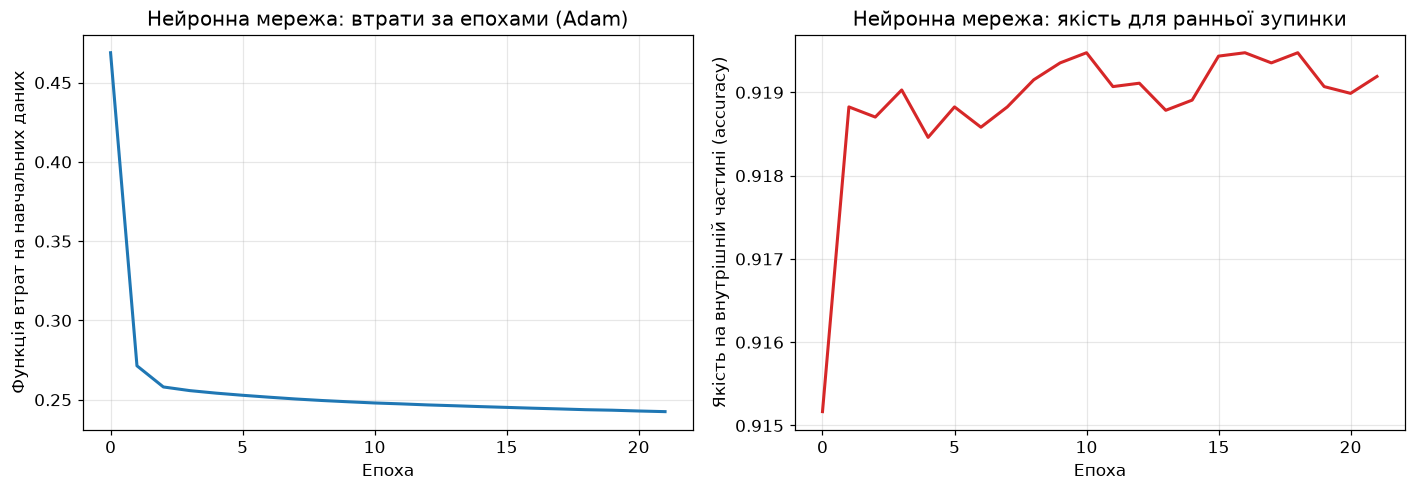

Перестановкова важливість обчислена за 9 с


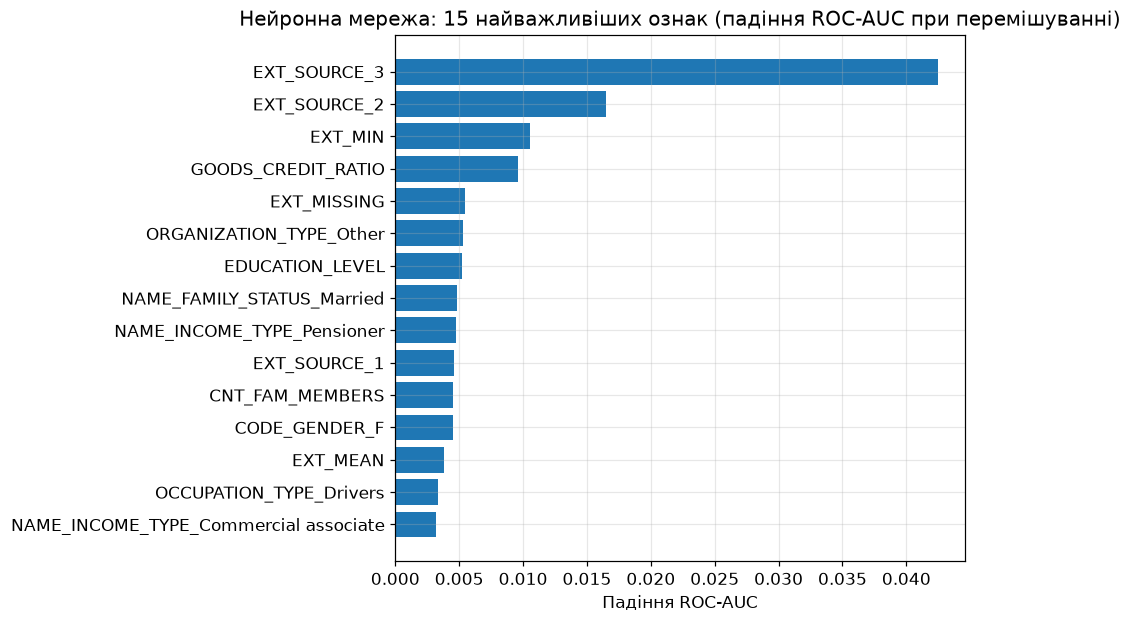

NAME_INCOME_TYPE_Commercial associate    0.003167
OCCUPATION_TYPE_Drivers                  0.003328
EXT_MEAN                                 0.003837
CODE_GENDER_F                            0.004480
CNT_FAM_MEMBERS                          0.004551
EXT_SOURCE_1                             0.004600
NAME_INCOME_TYPE_Pensioner               0.004772
NAME_FAMILY_STATUS_Married               0.004828
EDUCATION_LEVEL                          0.005181
ORGANIZATION_TYPE_Other                  0.005328
EXT_MISSING                              0.005450
GOODS_CREDIT_RATIO                       0.009634
EXT_MIN                                  0.010514
EXT_SOURCE_2                             0.016509
EXT_SOURCE_3                             0.042444
dtype: float64

In [21]:
# --- 8.3 Нейронна мережа: крива навчання та перестановкова важливість ---

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].plot(mlp_net.loss_curve_, color='#1f77b4', linewidth=2)
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Функція втрат на навчальних даних')
axes[0].set_title('Нейронна мережа: втрати за епохами (Adam)')
axes[1].plot(mlp_net.validation_scores_, color='#d62728', linewidth=2)
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Якість на внутрішній частині (accuracy)')
axes[1].set_title('Нейронна мережа: якість для ранньої зупинки')
plt.tight_layout()
plt.show()

# Перестановкова важливість на тій самій вибірці з 10 000 рядків валідації
start = time.time()
perm = permutation_importance(mlp_tuned, A_val_perm, y_val_perm, scoring='roc_auc',
                              n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
mlp_importance = pd.Series(perm.importances_mean, index=feature_names)
importances['Нейронна мережа'] = mlp_importance
print(f"Перестановкова важливість обчислена за {time.time() - start:.0f} с")

top_bar(mlp_importance, 'Нейронна мережа: 15 найважливіших ознак (падіння ROC-AUC при перемішуванні)', 'Падіння ROC-AUC')

**Результат.** За замовчуванням (один шар зі 100 нейронів, `relu`) нейромережа дала 0.7405, після підбору — **0.7418** (+0.0013, у межах шуму): один шар із 64 нейронів, `tanh`, `alpha = 0.017`, дуже малий початковий крок `learning_rate_init = 0.00016`, міні-батч 256. Вона **слабша за логістичну регресію** (0.7418 проти 0.7509), хоча складніша, потребує масштабування та підбору п'яти гіперпараметрів і навчається довше (36 с проти 4 с).

**Збіжність.** Криві показують те, що розповідалося в лекції №10: функція втрат різко падає за перші дві епохи й далі спадає повільно (Adam швидко знаходить область мінімуму). Ранню зупинку `MLPClassifier` виконує за **accuracy** на внутрішній частині даних, а при 92 % рядків класу 0 вона майже не змінюється (0.915–0.919) і не відображає якості ранжування. Тому момент зупинки (22-га епоха) не обов'язково оптимальний для ROC-AUC. Це обмеження конкретної реалізації: із критерієм за AUC мережа могла б вийти трохи краще.

**Інтерпретація.** Нейромережа — «чорна скринька»: ваги з'єднань нічого не кажуть про окремі ознаки, тож використано перестановкову важливість. Картина схожа на логістичну регресію: очолюють `EXT_SOURCE_3`, `EXT_SOURCE_2` та `EXT_MIN` (див. таблицю в п. 9.2).

## 9. Порівняння моделей

Зводимо результати п'яти моделей: якість на валідації до і після підбору гіперпараметрів, витрати часу на пошук і навчання.

                     AUC замовч.  AUC підібр.  Приріст  AUC крос-вал.  Навч. замовч., с  Пошук, с  Навч. підібр., с  Прогноз, с
Модель                                                                                                                         
Логістична регресія       0.7514       0.7509  -0.0005         0.7446            4.5287   25.1436            3.7677      0.1331
Дерево рішень             0.5432       0.7273   0.1840         0.7157           37.5499   43.8434           17.8310      0.0892
Випадковий ліс            0.7248       0.7500   0.0252         0.7426           32.9264  714.4097           43.9486      0.6616
Градієнтний бустинг       0.7662       0.7663   0.0001         0.7525           10.3467  195.0146            8.5830      0.4355
Нейронна мережа           0.7405       0.7418   0.0013         0.7269           58.0104   63.6490           35.7544      0.2400


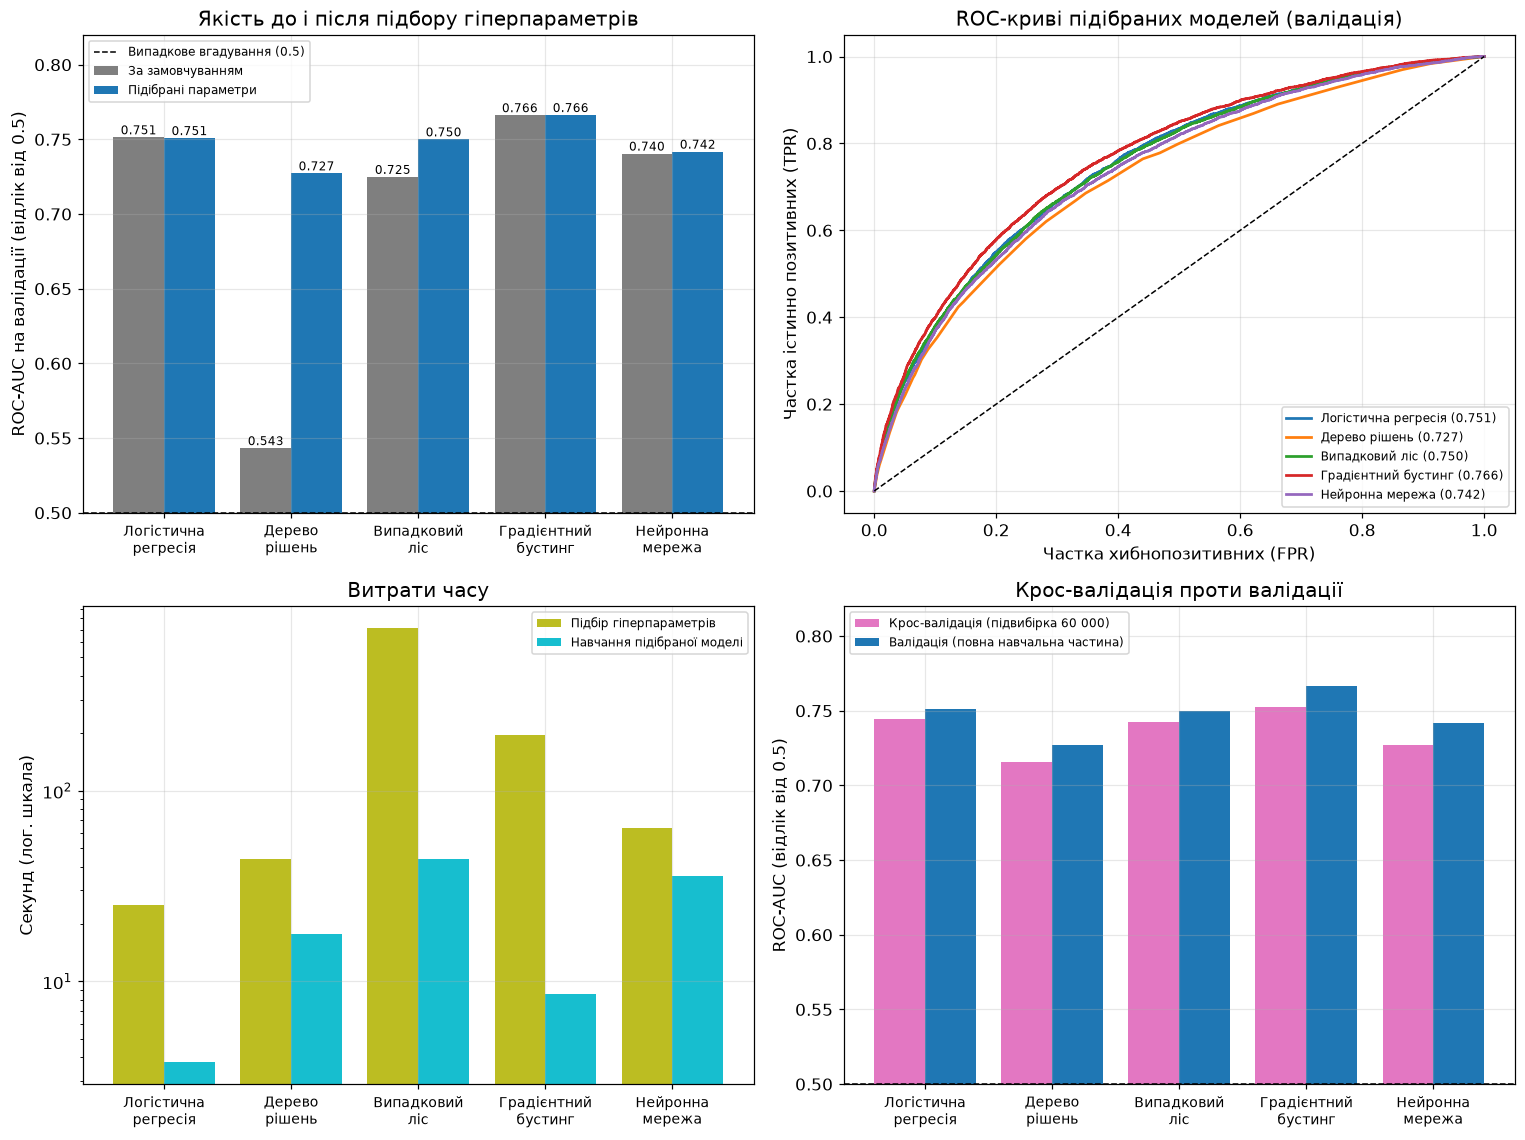

In [22]:
# --- 9.1 Зведена таблиця та графіки ---

order = ['Логістична регресія', 'Дерево рішень', 'Випадковий ліс', 'Градієнтний бустинг', 'Нейронна мережа']
table = pd.DataFrame(results)
default = table[table['Етап'] == 'За замовчуванням'].set_index('Модель').loc[order]
tuned = table[table['Етап'] == 'Підібрані параметри'].set_index('Модель').loc[order]

summary = pd.DataFrame({
    'AUC замовч.': default['ROC-AUC'],
    'AUC підібр.': tuned['ROC-AUC'],
    'Приріст': tuned['ROC-AUC'] - default['ROC-AUC'],
    'AUC крос-вал.': [searches[m]['cv_auc'] for m in order],
    'Навч. замовч., с': default['Навчання, с'],
    'Пошук, с': [searches[m]['time'] for m in order],
    'Навч. підібр., с': tuned['Навчання, с'],
    'Прогноз, с': tuned['Прогноз, с'],
})
print(summary.round(4).to_string())

fig, axes = plt.subplots(2, 2, figsize=(14, 10.5))
colors = ['#7f7f7f', '#1f77b4']

# (а) ROC-AUC до і після підбору (відлік від 0.5 — випадкового вгадування)
x = np.arange(len(order))
axes[0, 0].bar(x - 0.2, default['ROC-AUC'], 0.4, label='За замовчуванням', color=colors[0])
axes[0, 0].bar(x + 0.2, tuned['ROC-AUC'], 0.4, label='Підібрані параметри', color=colors[1])
for i, m in enumerate(order):
    axes[0, 0].text(i - 0.2, default.loc[m, 'ROC-AUC'], f"{default.loc[m, 'ROC-AUC']:.3f}", ha='center', va='bottom', fontsize=8)
    axes[0, 0].text(i + 0.2, tuned.loc[m, 'ROC-AUC'], f"{tuned.loc[m, 'ROC-AUC']:.3f}", ha='center', va='bottom', fontsize=8)
axes[0, 0].axhline(0.5, color='black', linestyle='--', linewidth=1, label='Випадкове вгадування (0.5)')
axes[0, 0].set_ylim(0.5, 0.82)
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels([m.replace(' ', '\n') for m in order], fontsize=9)
axes[0, 0].set_ylabel('ROC-AUC на валідації (відлік від 0.5)')
axes[0, 0].set_title('Якість до і після підбору гіперпараметрів')
axes[0, 0].legend(loc='upper left', fontsize=8)

# (б) ROC-криві підібраних моделей
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for m, c in zip(order, palette):
    fpr, tpr, _ = roc_curve(y_val, fitted[(m, 'Підібрані параметри')][1])
    axes[0, 1].plot(fpr, tpr, color=c, linewidth=1.8, label=f"{m} ({tuned.loc[m, 'ROC-AUC']:.3f})")
axes[0, 1].plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1)
axes[0, 1].set_xlabel('Частка хибнопозитивних (FPR)')
axes[0, 1].set_ylabel('Частка істинно позитивних (TPR)')
axes[0, 1].set_title('ROC-криві підібраних моделей (валідація)')
axes[0, 1].legend(loc='lower right', fontsize=8)

# (в) час: пошук гіперпараметрів та навчання підібраної моделі (лог. шкала)
axes[1, 0].bar(x - 0.2, summary['Пошук, с'], 0.4, label='Підбір гіперпараметрів', color='#bcbd22')
axes[1, 0].bar(x + 0.2, summary['Навч. підібр., с'], 0.4, label='Навчання підібраної моделі', color='#17becf')
axes[1, 0].set_yscale('log')
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels([m.replace(' ', '\n') for m in order], fontsize=9)
axes[1, 0].set_ylabel('Секунд (лог. шкала)')
axes[1, 0].set_title('Витрати часу')
axes[1, 0].legend(fontsize=8)

# (г) узгодженість: AUC крос-валідації на підвибірці та AUC на валідації
axes[1, 1].bar(x - 0.2, summary['AUC крос-вал.'], 0.4, label='Крос-валідація (підвибірка 60 000)', color='#e377c2')
axes[1, 1].bar(x + 0.2, summary['AUC підібр.'], 0.4, label='Валідація (повна навчальна частина)', color=colors[1])
axes[1, 1].axhline(0.5, color='black', linestyle='--', linewidth=1)
axes[1, 1].set_ylim(0.5, 0.82)
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels([m.replace(' ', '\n') for m in order], fontsize=9)
axes[1, 1].set_ylabel('ROC-AUC (відлік від 0.5)')
axes[1, 1].set_title('Крос-валідація проти валідації')
axes[1, 1].legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

**Що показують таблиця й графіки**

- **Градієнтний бустинг — найкращий за ROC-AUC (0.7663)**, і навіть без підбору (0.7662) він випереджає всі інші моделі після підбору: логістична регресія 0.7509, випадковий ліс 0.7500, нейромережа 0.7418, дерево 0.7273.
- Порядок моделей за крос-валідацією на підвибірці (бустинг 0.7525, логістична регресія 0.7446, ліс 0.7426, нейромережа 0.7269, дерево 0.7157) **повністю збігається** з порядком на валідації. Отже, підбір не «підлаштувався» під валідацію, а вибір моделі стабільний. Оцінки крос-валідації нижчі на 0.006–0.015, бо там модель вчиться лише на 40 000 рядків замість 246 008.
- Підбір гіперпараметрів суттєво допоміг двом моделям: дереву (+0.1840) і лісу (+0.0252). Для логістичної регресії, бустингу та нейромережі приріст у межах ±0.0013.
- Найдорожчий пошук у випадкового лісу (714 с), далі бустинг (195 с); логістична регресія — 25 с.

In [23]:
# --- 9.2 Найважливіші ознаки кожної моделі ---

# П'ять найважливіших ознак кожної моделі (способи оцінки різні, тому порівнюємо лише порядок)
top5 = pd.DataFrame({m: list(importances[m].sort_values(ascending=False).head(5).index) for m in order},
                    index=[f"{i}-а" for i in range(1, 6)])
print(top5.T.to_string())

# Ознаки, що потрапили до топ-10 принаймні трьох моделей із п'яти
from collections import Counter
counter = Counter(name for m in order for name in importances[m].sort_values(ascending=False).head(10).index)
common = [(name, count) for name, count in counter.most_common() if count >= 3]
print("\nОзнаки з топ-10 принаймні трьох моделей:")
for name, count in common:
    print(f"  {name:<28} у {count} моделях із 5")

                              1-а                 2-а                 3-а                 4-а              5-а
Логістична регресія  EXT_SOURCE_3        EXT_SOURCE_2            EXT_MEAN  GOODS_CREDIT_RATIO          EXT_MIN
Дерево рішень            EXT_MEAN  GOODS_CREDIT_RATIO            EXT_PROD        EXT_SOURCE_3          EXT_MAX
Випадковий ліс           EXT_MEAN             EXT_MAX             EXT_MIN            EXT_PROD     EXT_SOURCE_3
Градієнтний бустинг      EXT_MEAN         CREDIT_TERM  GOODS_CREDIT_RATIO        EXT_SOURCE_3  EDUCATION_LEVEL
Нейронна мережа      EXT_SOURCE_3        EXT_SOURCE_2             EXT_MIN  GOODS_CREDIT_RATIO      EXT_MISSING

Ознаки з топ-10 принаймні трьох моделей:
  EXT_SOURCE_3                 у 5 моделях із 5
  GOODS_CREDIT_RATIO           у 5 моделях із 5
  EXT_MEAN                     у 4 моделях із 5
  EXT_SOURCE_2                 у 3 моделях із 5
  EXT_MIN                      у 3 моделях із 5
  EDUCATION_LEVEL              у 3 моделях із 5
  EX

Незважаючи на різну природу моделей, **картина ознак вражаюче схожа**: `EXT_SOURCE_3` та `GOODS_CREDIT_RATIO` увійшли до топ-10 усіх п'яти моделей, `EXT_MEAN` — чотирьох. Найсильніший сигнал — зовнішні оцінки та відношення вартості товару до кредиту, і всі моделі знаходять його незалежно одна від одної. Це підвищує довіру до висновку про ключові ознаки.

**Зв'язок із лабораторною №3.** `EXT_MEAN`, `EXT_MIN`, `EXT_MAX`, `EXT_PROD`, `GOODS_CREDIT_RATIO`, `CREDIT_TERM`, `EXT_MISSING` та `EDUCATION_LEVEL` створено нами, і вони займають провідні місця в таблиці. У лабораторній №3 на дереві без обмежень вони дали лише +0.0050, а тепер видно, що ознаки корисні: їх активно використовують усі регуляризовані моделі. Тобто мізерний приріст там був наслідком перенавчання дерева, а не слабкості ознак.

## 10. Аналіз результатів та вибір найкращої моделі

Відповіді на питання з умови лабораторної. Усі числа взято з таблиці п. 9.1 та виводів вище.

**1. Вплив вибору моделі на якість класифікації.** Вибір моделі — найвпливовіше рішення в усій серії лабораторних. На тих самих ознаках підібрані моделі розкидані від 0.7273 (дерево) до 0.7663 (градієнтний бустинг), тобто на 0.039 AUC; для порівняння, уся інженерія ознак лабораторної №3 дала на дереві без обмежень +0.0050. Моделі розпалися на три групи: бустинг (0.766) — явно найкращий; логістична регресія, випадковий ліс і нейромережа (0.742–0.751) — близькі між собою; дерево (0.727) — найслабше. Перевага бустингу над кожною іншою моделлю статистично значуща (парний бутстреп у п. 10).

**2. Вплив підбору гіперпараметрів.** Нерівномірний. Для моделей, чиї параметри за замовчуванням не обмежують складність, підбір вирішальний: дерево +0.1840, випадковий ліс +0.0252. Для моделей, що вже регуляризовані за замовчуванням, він майже нічого не дав: логістична регресія −0.0005, бустинг +0.0001, нейромережа +0.0013 (у межах шуму). Підбір виправляє лише слабкості параметрів за замовчуванням і не піднімає модель над її «стелею». Крім того, крос-валідація правильно відтворила порядок моделей, тож підбір не призвів до перенавчання на валідацію.

**3. Складність навчання.** Час залежить від машини та фонового навантаження, тому важливі співвідношення, а не секунди.

| Модель | Навчання (замовч.), с | Пошук гіперпараметрів, с | Навчання (підібр.), с | Прогноз 61 503 рядків, с |
|---|---|---|---|---|
| Логістична регресія | 4.5 | 25 | 3.8 | 0.13 |
| Дерево рішень | 37.5 | 44 | 17.8 | 0.09 |
| Випадковий ліс | 32.9 | 714 | 43.9 | 0.66 |
| Градієнтний бустинг | 10.3 | 195 | 8.6 | 0.44 |
| Нейронна мережа | 58.0 | 64 | 35.8 | 0.24 |

Найдешевша — логістична регресія. Найдорожчий пошук у лісу (714 с, у 28 разів дорожче, ніж для логістичної регресії), хоча результат лісу не кращий. Бустинг найкраще поєднує якість і швидкість: навчається швидше за ліс і нейромережу та має найвищий AUC. Дерево за замовчуванням навчається довго (37.5 с) саме через повну глибину, а після підбору вдвічі швидше.

**4. Інтерпретованість.** Від прозорої до непрозорої: *дерево рішень* (набір правил, які можна прочитати) і *логістична регресія* (коефіцієнти зі знаком і величиною) пояснюють не лише «які ознаки», а й «у який бік»; *випадковий ліс* і *градієнтний бустинг* дають лише важливість ознак (за gini або перестановкову), без напрямку та форми залежності; *нейронна мережа* — «чорна скринька». Інтерпретовані моделі коштують якості: від 0.015 AUC (логістична регресія) до 0.039 (дерево) проти бустингу.

**5. Доцільність кожної моделі для цієї задачі.**

| Модель | Висновок |
|---|---|
| Логістична регресія | Сильний простий базис (0.7509) за 4 секунди, повністю пояснювана. Доцільна, якщо потрібна повна прозорість рішень |
| Дерево рішень | Прогнозує найгірше (0.7273); корисне лише як ілюстрація логіки, не як основна модель |
| Випадковий ліс | Недоцільний: найдорожчий пошук (714 с), важка модель (234 дерева), а AUC нижчий за логістичну регресію |
| Градієнтний бустинг | **Найкращий вибір**: найвищий AUC (0.7663), швидке навчання (8.6 с), мала чутливість до параметрів |
| Нейронна мережа | Недоцільна: слабша за логістичну регресію (0.7418), складніша, непрозора; на табличних даних бустинг зазвичай не поступається нейромережам |

In [24]:
# --- 10. Вибір моделі та перевірка значущості різниці (парний бутстреп) ---

# Обираємо модель з найвищим ROC-AUC на валідації серед підібраних
best_family = tuned['ROC-AUC'].idxmax()
print(f"Найвищий ROC-AUC на валідації: {best_family} ({tuned.loc[best_family, 'ROC-AUC']:.4f})\n")

# Чи достатня різниця між найкращою та іншими моделями, щоб не списати її на випадковість валідаційної вибірки?
# Парний бутстреп: 200 разів перевибираємо рядки валідації з поверненням і рахуємо різницю AUC на тих самих рядках.
rng = np.random.RandomState(RANDOM_STATE)
y_true = y_val.values
best_proba = fitted[(best_family, 'Підібрані параметри')][1]
n = len(y_true)
boot_idx = [rng.randint(0, n, n) for _ in range(200)]

print(f"{'Порівняння з':<24}{'Різниця AUC':>12}{'95 % інтервал':>24}")
for m in order:
    if m == best_family:
        continue
    other = fitted[(m, 'Підібрані параметри')][1]
    diffs = [roc_auc_score(y_true[i], best_proba[i]) - roc_auc_score(y_true[i], other[i]) for i in boot_idx]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    print(f"{m:<24}{tuned.loc[best_family, 'ROC-AUC'] - tuned.loc[m, 'ROC-AUC']:>+12.4f}   [{lo:+.4f}; {hi:+.4f}]")

Найвищий ROC-AUC на валідації: Градієнтний бустинг (0.7663)

Порівняння з             Різниця AUC           95 % інтервал


Логістична регресія          +0.0154   [+0.0127; +0.0181]


Дерево рішень                +0.0390   [+0.0348; +0.0432]


Випадковий ліс               +0.0163   [+0.0138; +0.0185]


Нейронна мережа              +0.0245   [+0.0211; +0.0279]


**Обрана модель — градієнтний бустинг** (`HistGradientBoostingClassifier` з підібраними параметрами). Обґрунтування:

1. **Найвища якість.** ROC-AUC 0.7663 на валідації. Перевага над кожною іншою моделлю статистично значуща: різниця AUC від +0.0154 (логістична регресія) до +0.0390 (дерево), а нижні межі 95 % інтервалів (від +0.0127 до +0.0348) лежать вище за нуль.
2. **Швидкість.** Навчання на 246 тисячах рядків триває 8.6 с (швидше, ніж у лісу — 43.9 с чи нейромережі — 35.8 с), пошук гіперпараметрів — 195 с.
3. **Практичність.** Бустинг не потребує масштабування ознак, уміє обробляти пропуски самостійно (ми їх імпутували лише для однакових умов порівняння) і мало чутливий до гіперпараметрів: параметри за замовчуванням дали майже той самий результат (0.7662).
4. **Узгодженість із іншими моделями.** Його найважливіші ознаки збігаються з тими, що знайшли інші моделі (п. 9.2), тож висновок про ключовий сигнал не залежить від вибору алгоритму.

**Чим доводиться поступитися.** Прямою інтерпретованістю: бустинг пояснюється лише перестановковою важливістю, а не коефіцієнтами. Якщо для кредитного скорингу потрібна повна прозорість, розумний компроміс — логістична регресія: вона на 0.0154 AUC гірша, але кожне її рішення можна пояснити клієнту.

**Застереження.** Модель обрано за найвищим AUC на валідації, тому ця оцінка трохи оптимістична, хоча валідація для підбору параметрів не використовувалась. Незалежну перевірку дасть Kaggle (розділ 12).

## 11. Прогноз для тестових даних та submission-файл

Класифікуємо `application_test.csv` обраною моделлю (навченою на навчальній частині, з підібраними гіперпараметрами). Тестові дані проходять ті самі перетворення ознак і ту саму обробку, параметри яких визначено за навчальною частиною. У файл записуємо **ймовірність класу 1**, а не мітку: метрика змагання теж ROC-AUC.

In [25]:
# --- 11. Прогноз для application_test.csv та формування submission.csv ---

# Обрана модель і її ймовірності класу 1 для тестових рядків
best_model = fitted[(best_family, 'Підібрані параметри')][0]
test_proba = best_model.predict_proba(A_test)[:, 1]

# Таблиця submission: ідентифікатор заявки та ймовірність; зберігаємо без індексу
submission = pd.DataFrame({'SK_ID_CURR': test_ids.values, 'TARGET': test_proba})
submission.to_csv('submission.csv', index=False)
print(f"Модель: {best_family}")
print(f"Збережено submission.csv: {submission.shape[0]} рядків, колонки: {list(submission.columns)}")
print("\nПерші 5 рядків:")
print(submission.head().to_string(index=False))

# Розподіл прогнозованих ймовірностей: порівнюємо з частотою класу 1 у навчальних даних (8.07 %)
print(f"\nСередня ймовірність у тесті: {test_proba.mean():.4f} (частка класу 1 у навчальній частині: {y_train.mean():.4f})")
print(f"Мінімум {test_proba.min():.4f}, медіана {np.median(test_proba):.4f}, максимум {test_proba.max():.4f}")

# Перевірка формату за зразком sample_submission.csv (якщо файл поруч)
try:
    sample = pd.read_csv(find_file('sample_submission.csv'))
    print(f"\nЗбіг із sample_submission.csv: колонки — {list(sample.columns) == list(submission.columns)}, "
          f"кількість рядків — {len(sample) == len(submission)}, "
          f"набір SK_ID_CURR — {set(sample['SK_ID_CURR']) == set(submission['SK_ID_CURR'])}")
except FileNotFoundError:
    print("\nsample_submission.csv не знайдено — перевірку формату пропущено.")

Модель: Градієнтний бустинг
Збережено submission.csv: 48744 рядків, колонки: ['SK_ID_CURR', 'TARGET']

Перші 5 рядків:
 SK_ID_CURR   TARGET
     100001 0.027864
     100005 0.108723
     100013 0.018091
     100028 0.032533
     100038 0.150206

Середня ймовірність у тесті: 0.0805 (частка класу 1 у навчальній частині: 0.0807)
Мінімум 0.0043, медіана 0.0526, максимум 0.7437

Збіг із sample_submission.csv: колонки — True, кількість рядків — True, набір SK_ID_CURR — True


## 12. Результат на Kaggle (Late Submission)

Файл `submission.csv` (48744 рядки: `SK_ID_CURR` та ймовірність класу 1), створений у розділі 11, завантажено на Kaggle у розділ **Late Submission** змагання Home Credit Default Risk. Змагання завершилось у 2018 році, тому подання позначається як «після дедлайну» й у таблицю лідерів не потрапляє, але оцінку Kaggle рахує так само: за ROC-AUC на прихованих відповідях для `application_test.csv`.

Нижче знімок вкладки «Подання» (Submissions). Верхній рядок (`submission (3).csv`) — подання цієї лабораторної; нижче — подання лабораторної №3 (`submission (2).csv`) та лабораторної №2 (`submission.csv`).

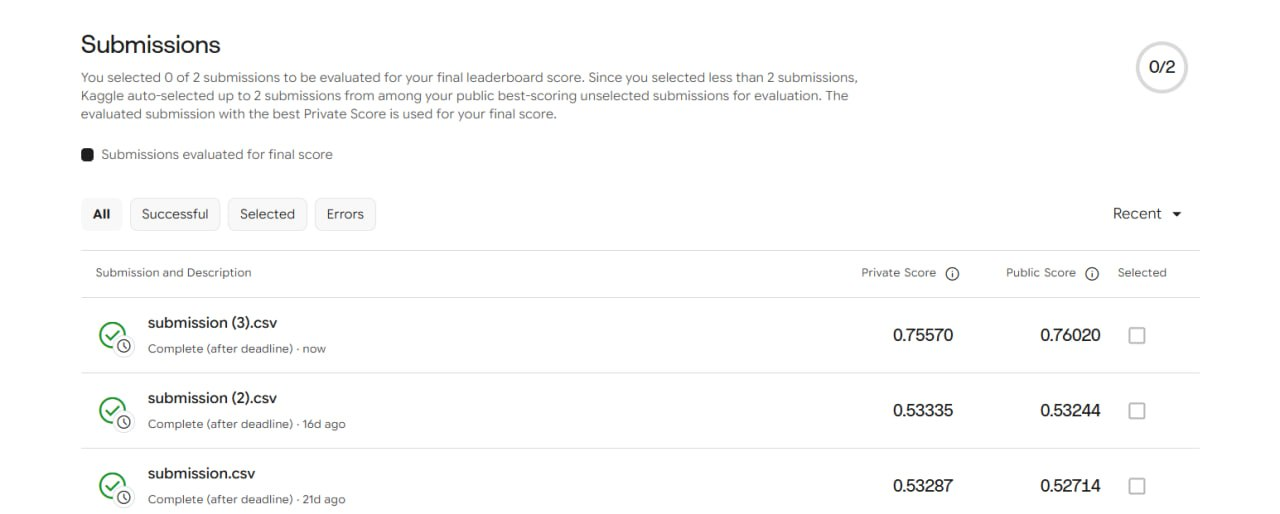

In [26]:
# --- Знімок екрана з результатом на Kaggle ---

# Імпорт засобів для показу зображення в ноутбуці
from IPython.display import Image, display

# Знімок лежить у підкаталозі images/ поруч із ноутбуком
SCREENSHOT = os.path.join('images', 'kaggle_result.png')

if os.path.exists(SCREENSHOT):
    # Показуємо знімок вкладки "Подання" з оцінками Public та Private
    display(Image(filename=SCREENSHOT, width=950))
else:
    print(f"Знімок {SCREENSHOT} не знайдено: покладіть його в підкаталог images/.")

### Порівняння оцінок

На знімку: для цієї лабораторної **Public score = 0.76020**, **Private score = 0.75570**; для лабораторної №3 (одне дерево без обмежень) — 0.53244 та 0.53335. Порівняємо з валідацією:

| Де оцінено | Лаб. №3 (дерево) | Лаб. №4 (градієнтний бустинг) | Різниця |
|---|---|---|---|
| Валідація (20 % application_train) | 0.5432 | 0.7663 | +0.2231 |
| Kaggle, Public score | 0.53244 | 0.76020 | +0.2278 |
| Kaggle, Private score | 0.53335 | 0.75570 | +0.2224 |

**Що показує порівняння.**

- Приріст над лабораторною №3 підтвердився на Kaggle: +0.2278 (Public) та +0.2224 (Private) майже збігаються з +0.2231 на валідації. Отже, стрибок — не артефакт нашого розділення даних.
- Причина стрибка — не нові ознаки (вони ті самі), а перехід від «жорсткої» відповіді до ранжування. Дерево без обмежень дає в листках майже чисті 0 або 1, і ROC-AUC такого прогнозу лежить поблизу 0.5. Градієнтний бустинг віддає плавні ймовірності, за якими заявки можна впорядкувати за ризиком (розділи 5 та 7).
- Оцінки Kaggle нижчі за валідаційну 0.7663 на 0.0061 (Public) та 0.0106 (Private). Стандартна похибка AUC на нашій валідації, за формулою Ханлі та Мак-Ніла, близько 0.004 (4965 позитивних із 61503 рядків), а до неї додається похибка самого Kaggle-тесту, який менший (48744 рядки; Public і Private рахуються на його частинах). Тому розрив того ж порядку, що й шум вибірки. Валідація не брала участі в підборі гіперпараметрів, тож зсув через підбір малий. Відрізнити шум від невеликого систематичного зсуву за двома числами не можна. Зауважимо лише, що на Private у лабораторній №3 розрив був майже такий самий (0.0099): обидві моделі оцінюються на тих самих рядках, тому шум тестової вибірки в них, імовірно, спільний.
- Kaggle перевірив лише одну модель, яку ми обрали. Перевагу бустингу над логістичною регресією, лісом та нейромережею він не перевіряв: вона підтверджена бутстрепом на валідації (розділ 10).
- Абсолютне значення не слід порівнювати з таблицею лідерів змагання: ми використали лише таблиці `application_train` та `application_test`, а змагання пропонує ще кілька допоміжних таблиць (історія в бюро кредитних історій, попередні заявки, платежі), які в цій роботі не залучались.

## Висновки

1. **Лабораторну №3 продовжено**: ті самі дані, розділення 80/20 (`stratify`, `random_state=42`), метрика ROC-AUC і підсумковий набір ознак (107 ознак, 181 після обробки). Змінилось головне: замість одного дерева порівняно **п'ять алгоритмів** із курсу.

2. **Для кожної моделі** виконано однакову схему: параметри за замовчуванням, підбір гіперпараметрів (Grid Search для дерева, Random Search для решти; 3-кратна стратифікована крос-валідація на підвибірці з 60 000 рядків; валідація в підборі не брала участі), навчання найкращої конфігурації на всій навчальній частині та оцінка на валідації, важливість ознак.

3. **Результат на валідації (ROC-AUC, за замовчуванням → після підбору):** логістична регресія 0.7514 → 0.7509; дерево рішень 0.5432 → 0.7273; випадковий ліс 0.7248 → 0.7500; градієнтний бустинг 0.7662 → **0.7663**; нейронна мережа 0.7405 → 0.7418.

4. **Вибір моделі важливіший за все інше:** розкид між найкращою та найслабшою підібраною моделлю — 0.039 AUC, а уся інженерія ознак лабораторної №3 дала на дереві +0.0050. Перевага градієнтного бустингу над кожною іншою моделлю статистично значуща (парний бутстреп).

5. **Підбір гіперпараметрів допоміг нерівномірно:** дереву (+0.1840) і лісу (+0.0252), у яких параметри за замовчуванням не обмежують складність; для логістичної регресії, бустингу та нейромережі приріст у межах шуму. Порядок моделей за крос-валідацією збігся з порядком на валідації.

6. **Ціна й прозорість:** найдорожчий пошук — у випадкового лісу (714 с), найдешевший — у логістичної регресії (25 с). Прозорі моделі (дерево, логістична регресія) поступаються бустингу на 0.039 та 0.015 AUC; нейромережа одночасно слабша й найменш прозора.

7. **Обрано градієнтний бустинг**: найвищий AUC, швидке навчання (8.6 с), мала чутливість до параметрів, природна робота з пропусками. Частиною прозорості доводиться поступитися; за потреби повної прозорості розумна альтернатива — логістична регресія.

8. **Практична цінність.** Найважливіші ознаки всіх моделей збігаються: `EXT_SOURCE_3`, `GOODS_CREDIT_RATIO` та створена нами `EXT_MEAN`. Ознаки з лабораторної №3, що дали лише +0.0050 на перенавченому дереві, активно використовують усі регуляризовані моделі: мізерний приріст там, імовірно, був наслідком перенавчання дерева, а не слабкості ознак.

9. **Незалежна перевірка на Kaggle (Late Submission):** Public score **0.76020**, Private score **0.75570**, тобто на 0.0061 та 0.0106 нижче за валідацію (0.7663). Розрив того ж порядку, що й похибка оцінки AUC (≈ 0.004 на валідації), тож висновок про рівень моделі підтвердився. Приріст над лабораторною №3 на Kaggle (+0.2278 та +0.2224) майже збігається з приростом на валідації (+0.2231). Kaggle перевірив лише обрану модель, тому перевагу бустингу над іншими моделями підтверджує бутстреп на валідації, а не Kaggle.